# Extreme Weather Album: Lightning Crosses the Equator

Issue #27. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md); the album's design is in [docs/albums/lightning.md](../docs/albums/lightning.md).

**The album's message, in EIC's words** ([5011](https://svs.gsfc.nasa.gov/5011/)): "This data uncovers the variability and distribution of lightning" and "A roving window of 10 days was used to visualize the seasonal patterns of lightning."

**The story this notebook checks, in the source data:**

1. **The data**: every flash the Lightning Imaging Sensor on the International Space Station saw in 2021, orbit by orbit.
2. **A fair count**: the station lingers near its turning latitudes and hurries over the equator, so the flashes are corrected for how long each latitude is watched.
3. **The belt follows the sun** (ours): the latitude where lightning gathers follows the latitude the noon sun stands over, about a month late and not as far, each landmass its own way.
4. **The season** (ours): seen from two sides of the Earth, lightning moves into the hemisphere having its summer and back again, the north taking the lead in spring and handing it back in autumn.

Section 8 turns this into the album's two tracks, one for each side of the Earth, exported to `data/extreme_weather/tracks/`.

Run with `npm run notebook`. Downloads go to `data/extreme_weather/raw/` (local only). Every source is public; no login is needed. The first run fetches about 6,000 pages (about 530 MB) and takes a while; later runs read them from disk.

In [1]:
import html
import json
import math
import re
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timedelta, timezone
from enum import Enum
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shapely
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/extreme_weather/raw")
TRACKS = Path("../data/extreme_weather/tracks")
(RAW / "api").mkdir(parents=True, exist_ok=True)
# A generic client name, no contact details.
HEADERS = {"User-Agent": "blue-vinyl-notebook"}


def download(name, url):
    """Download url into data/extreme_weather/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = requests.get(url, headers=HEADERS, timeout=120)
        response.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", " ", text or "")).split("Science on a Sphere")[0].strip()


def source_note(ax, text):
    ax.annotate(text, xy=(0, -0.2), xycoords="axes fraction", fontsize=8, color="gray")

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API, so they stay correct if EIC changes.

### 1.1 Where the visualization sits in the EIC gallery

In [2]:
EIC_GALLERY = 40467
PAGES = [5011]


def gallery_paths(gallery_id):
    """Each page id, with the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        for group in svs_page(page_id).get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] not in ("gallery_page", "details_page") or not inst.get("id"):
                    continue
                step = f"{group['title']} → [{inst['title']}]({inst['url'].replace('http://', 'https://')})"
                if inst.get("page_type") != "Gallery":
                    paths.setdefault(inst["id"], []).append(trail + [step])
                elif inst["id"] not in [t for t, _ in visited]:
                    visited.append((inst["id"], step))
                    walk(inst["id"], trail + [step])

    visited = []
    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
rows = ["| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |", "| --- | --- |"]
for page_id in PAGES:
    trails = sorted({" › ".join(trail) for trail in paths.get(page_id, [])})
    rows.append(f"| [{page_id}](https://svs.gsfc.nasa.gov/{page_id}/) | {'<br>'.join(trails)} |")
display(Markdown("\n".join(rows)))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [5011](https://svs.gsfc.nasa.gov/5011/) | EIC Beauty Pieces → [Lightning Events Detected from the International Space Station (ISS) 2017-2023](https://svs.gsfc.nasa.gov/5011/) |

### 1.2 What the page cites, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of the SVS page, as published.
- **Downloaded here** is what this notebook actually reads.
- The land on the maps (ours, not cited by EIC) is Natural Earth's 1:110m land polygons, [ne_110m_land](https://www.naturalearthdata.com/downloads/110m-physical-vectors/110m-land/) v5.1.2, public domain.

In [3]:
LISIB = "https://lightning.nsstc.nasa.gov/isslisib/"
LIS_V3 = "https://doi.org/10.5067/LIS/ISSLIS/DATA114"
YEAR = 2021


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = f"{d['name']} ({d.get('sensor') or d.get('organizations', [''])[0]})"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out)


DOWNLOADED = (
    f"[ISS LIS browser]({LISIB}) of NASA MSFC: the quality-controlled flash table of every orbit of {YEAR} "
    f"(`{LISIB}lisbrowse.exe?which=qc&year={YEAR}&day=<day>` lists a day's orbits, "
    f"`{LISIB}lis1orbit.exe?which=qc&year={YEAR}&day=<day>&orbit=<hhmmss>` is one orbit's table)"
)
NOTE = (
    "Substitute for the lightning data. EIC cites Quality Controlled LIS on ISS Science Data V1; that link no longer "
    f"answers, and the current version ([V3.0]({LIS_V3})) needs an Earthdata login on GHRC. The browser prints the "
    "same quality-controlled flashes publicly, one table per orbit. Public. The cloud composite and the Gray Earth "
    "basemap set the scene of 5011 and are not used."
)
display(Markdown("\n".join([
    "| SVS page | Cited by EIC | Downloaded here | Note |", "| --- | --- | --- | --- |",
    f"| [5011](https://svs.gsfc.nasa.gov/5011/) | {cited(5011)} | {DOWNLOADED} | {NOTE} |",
])))

| SVS page | Cited by EIC | Downloaded here | Note |
| --- | --- | --- | --- |
| [5011](https://svs.gsfc.nasa.gov/5011/) | CPC (Climate Prediction Center) Cloud Composite (Climate Prediction Center (CPC)), no link<br>[Gray Earth with Shaded Relief, Hypsography, and Flat Water (Natrual Earth)](https://www.naturalearthdata.com/downloads/10m-raster-data/10m-gray-earth/)<br>[Quality Controlled Lightning Imaging Sensor (LIS) on International Space Station (ISS) Science Data V1 (Lightning Imaging Sensor (LIS))](https://ghrcdrive.nsstc.nasa.gov/pub/lis/iss/data/science/final/nc/)<br>[Land Cover Climate Modeling Grid (CMG) (MODIS)](https://lpdaac.usgs.gov/products/mcd12c1v006/) | [ISS LIS browser](https://lightning.nsstc.nasa.gov/isslisib/) of NASA MSFC: the quality-controlled flash table of every orbit of 2021 (`https://lightning.nsstc.nasa.gov/isslisib/lisbrowse.exe?which=qc&year=2021&day=<day>` lists a day's orbits, `https://lightning.nsstc.nasa.gov/isslisib/lis1orbit.exe?which=qc&year=2021&day=<day>&orbit=<hhmmss>` is one orbit's table) | Substitute for the lightning data. EIC cites Quality Controlled LIS on ISS Science Data V1; that link no longer answers, and the current version ([V3.0](https://doi.org/10.5067/LIS/ISSLIS/DATA114)) needs an Earthdata login on GHRC. The browser prints the same quality-controlled flashes publicly, one table per orbit. Public. The cloud composite and the Gray Earth basemap set the scene of 5011 and are not used. |

## 2. What EIC says

The page's descriptions, as published.

In [4]:
def descriptions(page_id):
    page = svs_page(page_id)
    texts = [plain(page["description"].split(" || ")[0])]
    texts += [plain(g.get("description")) for g in page["media_groups"] if g.get("description")]
    return list(dict.fromkeys(t for t in texts if t))


display(Markdown(f"**[5011](https://svs.gsfc.nasa.gov/5011/) {svs_page(5011)['title']}**\n\n"
                 + "\n\n".join(f"> {t}" for t in descriptions(5011))))

**[5011](https://svs.gsfc.nasa.gov/5011/) Lightning Events Detected from the International Space Station (ISS) 2017-2023**

> Lightning events detected by the LIS sensor on the ISS between January 2017 and July 2023 using a 10-day roving window. Data is from the quality controlled science dataset. Available resolution in the download menu are 1920x1080, 3840x2160 (4k), and 7680x2160 (created for EIC display).

> The Lightning Imaging Sensor (LIS) on the International Space Station (ISS) detects lightning occurring in the Earth’s tropical and mid-latitude regions. The LIS provides datasets consisting of near-real time and non-quality controlled data as well as final quality controlled datasets that are manually reviewed. This data uncovers the variability and distribution of lightning and can be used for storm detection and lightning-atmosphere interaction studies.   This visualization shows the global distribution of lightning strikes between January 2017 and July 2023 using the final quality controlled science dataset. Each data point contains the latitude and longitude of the strike as well as the time it was detected by the LIS. A roving window of 10 days was used to visualize the seasonal patterns of lightning.

> Global lightning events detected by the LIS on the ISS between March 2017 and July 2023. Movie in 4096x2048 resolution for SOS display.

> Thumbnail image for SOS.

EIC shows where and when lightning strikes, season by season, without saying why. What we add (sections 5 and 6, ours): seen from either side of the Earth, the lightning gathers in whichever hemisphere is having its summer.

## 3. Source data: ISS LIS flashes of 2021

[5011](https://svs.gsfc.nasa.gov/5011/) · [ISS LIS browser](https://lightning.nsstc.nasa.gov/isslisib/) · [ISS LIS V3.0 dataset](https://doi.org/10.5067/LIS/ISSLIS/DATA114)

- **What**: every flash the Lightning Imaging Sensor saw, as the browser's quality-controlled table: its time (UTC, to the hundredth of a second), latitude and longitude (degrees), radiance, duration (ms), and how many groups and events it is made of.
- **Where**: under the space station, a view about 600 km square, between about 55° S and 55° N (the orbit is inclined 51.6°).
- **When**: 2021, every day. The browser has no orbits for July 20 to 22, and only a few on some other days.

Credit: Blakeslee, R. J., et al. Lightning Imaging Sensor (LIS) on the International Space Station (ISS). NASA Global Hydrometeorology Resource Center DAAC / NASA MSFC.

A day's page lists its orbits; each orbit's page holds its flashes. Pages are kept under `raw/isslis/2021/` with the day of the year and the orbit's start (`orbit_2021_<day>_<hhmmss>.html`).

In [5]:
LIS_DIR = RAW / "isslis" / str(YEAR)
ORBIT_LINK = re.compile(rf"lis1orbit\.exe\?which=qc&year={YEAR}&day=(\d+)&orbit=(\d+)")
DAYS = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D")
FETCH_WORKERS = 6


def fetch(name, url):
    """A page under LIS_DIR, fetched once; a page under 1 kB is an error page and is fetched again."""
    path = LIS_DIR / name
    if not path.exists() or path.stat().st_size < 1000:
        for attempt in range(4):
            try:
                response = requests.get(url, headers=HEADERS, timeout=120)
                response.raise_for_status()
                break
            except requests.RequestException:
                if attempt == 3:
                    raise
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    return path.read_text(encoding="latin-1")


def orbits_of(day):
    """The (day of year, orbit start hhmmss) of every orbit the browser lists on `day`."""
    doy = day.day_of_year
    page = fetch(f"day_{YEAR}_{doy:03d}.html", f"{LISIB}lisbrowse.exe?which=qc&year={YEAR}&day={doy}")
    return sorted({(int(d), hms) for d, hms in ORBIT_LINK.findall(page)})


def orbit_page(orbit):
    doy, hms = orbit
    return fetch(f"orbit_{YEAR}_{doy:03d}_{hms}.html", f"{LISIB}lis1orbit.exe?which=qc&year={YEAR}&day={doy}&orbit={hms}")


with ThreadPoolExecutor(FETCH_WORKERS) as pool:
    orbits = [o for day_orbits in pool.map(orbits_of, DAYS) for o in day_orbits]
    list(pool.map(orbit_page, orbits))
print(f"{len(DAYS)} day pages, {len(orbits):,} orbit pages")

365 day pages, 5,634 orbit pages


Each flash is one row of an orbit's table: time, date, latitude, longitude, radiance, duration, groups and events. A flash belongs to the day its orbit is listed on.

In [6]:
FLASH_ROW = re.compile(r'<tr class="filelist(?:one|two)">((?:\s*<td[^>]*>[^<]*</td>){8})')
CELL = re.compile(r"<td[^>]*>([^<]*)</td>")
FLASH_COLUMNS = ["time", "lat", "lon", "radiance", "ms", "groups", "events"]
FLASHES_CACHE = RAW / "isslis" / f"flashes_{YEAR}.csv.gz"


def lis_time(text):
    """A browser time such as 2021-180T00:31:52.09Z, as a UTC timestamp."""
    year, rest = text.split("-", 1)
    doy, clock = rest.rstrip("Z").split("T")
    h, m, s = clock.split(":")
    return datetime(int(year), 1, 1) + timedelta(days=int(doy) - 1, hours=int(h), minutes=int(m), seconds=float(s))


def flashes_of(orbit):
    doy, hms = orbit
    rows = []
    for match in FLASH_ROW.finditer(orbit_page(orbit)):
        time, _, lat, lon, radiance, ms, groups, events = CELL.findall(match.group(1))
        rows.append((lis_time(time.strip()), float(lat), float(lon), int(radiance), int(ms), int(groups), int(events)))
    if not rows:
        return None
    out = pd.DataFrame(rows, columns=FLASH_COLUMNS)
    out["orbit"] = f"{doy:03d}_{hms}"
    out["day"] = pd.Timestamp(YEAR, 1, 1) + pd.Timedelta(days=doy - 1)
    return out


if FLASHES_CACHE.exists():
    flashes = pd.read_csv(FLASHES_CACHE, parse_dates=["time", "day"])
else:
    flashes = pd.concat([flashes_of(o) for o in orbits], ignore_index=True)
    flashes.to_csv(FLASHES_CACHE, index=False)
per_day = flashes.groupby("day").orbit.nunique().reindex(DAYS, fill_value=0)
print(f"{len(flashes):,} flashes from {flashes.orbit.nunique():,} orbits with lightning "
      f"(of {len(orbits):,} listed), {flashes.time.min()} to {flashes.time.max()}")
print("days without orbits:", ", ".join(d.strftime("%b %d") for d in per_day.index[per_day == 0]))
print("days with fewer than 8 orbits:", ", ".join(f"{d:%b %d} ({n})" for d, n in per_day[(per_day > 0) & (per_day < 8)].items()))
flashes.head()

956,126 flashes from 5,490 orbits with lightning (of 5,634 listed), 2021-01-01 01:09:30.850000 to 2021-12-31 23:44:09.060000
days without orbits: Jul 20, Jul 21, Jul 22
days with fewer than 8 orbits: Feb 24 (1), Jun 20 (5), Jul 19 (5)


,time,lat,lon,radiance,ms,groups,events,orbit,day
0,2021-01-01 01:09:30.850,-26.063,-52.646,41791,159,3,6,001_005536,2021-01-01
1,2021-01-01 01:09:32.480,-27.003,-49.139,9987,14,2,2,001_005536,2021-01-01
2,2021-01-01 01:09:32.630,-26.967,-49.180,17190,27,4,4,001_005536,2021-01-01
3,2021-01-01 01:09:32.910,-26.980,-49.134,163224,177,6,13,001_005536,2021-01-01
4,2021-01-01 01:09:35.080,-26.091,-52.576,81922,1,2,11,001_005536,2021-01-01


### 3.1 One orbit's table

The busiest orbit of the year (about 92 minutes) on a map, and its first rows. The station circles the whole Earth, but its flashes land in clumps over the few storms it passes. One orbit sees a sliver of the Earth; the season shows only when hundreds of orbits are put together.

,time,lat,lon,radiance,ms,groups,events
450837,2021-07-10 18:20:11.610,-3.296,19.830,477844,411,20,44
450838,2021-07-10 18:20:15.160,-5.114,19.215,47024,152,4,9
450839,2021-07-10 18:20:15.580,-3.380,19.929,516524,544,19,58
450840,2021-07-10 18:20:15.810,-3.627,19.919,54240,123,5,11
450841,2021-07-10 18:20:16.490,-3.882,20.088,42614,252,3,9


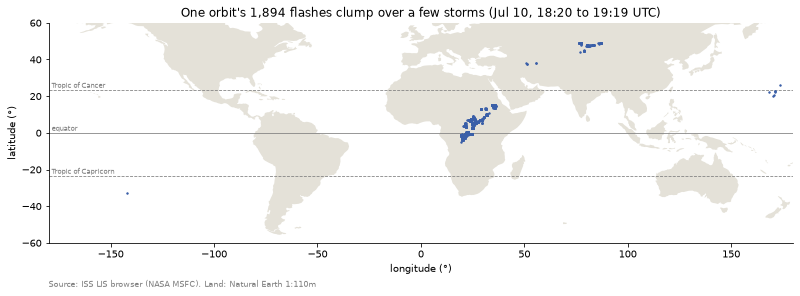

In [7]:
NATURAL_EARTH = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/v5.1.2/geojson"
land = [shapely.geometry.shape(f["geometry"]) for f in
        json.loads(download("natural_earth/ne_110m_land.geojson", f"{NATURAL_EARTH}/ne_110m_land.geojson").read_text())["features"]]
TROPIC_DEG = 23.44
LAND_COLOR, FLASH_COLOR = "#e4e1d8", "#3a5fa8"


def draw_land(ax, shifts=(0,)):
    """Natural Earth's land under a latitude-longitude plot, repeated `shifts` degrees east for views across 180°."""
    for shift in shifts:
        for shape in land:
            for polygon in getattr(shape, "geoms", [shape]):
                xs, ys = polygon.exterior.xy
                ax.fill(np.asarray(xs) + shift, ys, color=LAND_COLOR, linewidth=0, zorder=0)


def draw_tropics(ax, names=True):
    """The equator and the two tropics; set the plot's limits first."""
    for lat, name in ((TROPIC_DEG, "Tropic of Cancer"), (0, "equator"), (-TROPIC_DEG, "Tropic of Capricorn")):
        ax.axhline(lat, color="gray", linewidth=0.8, linestyle="-" if lat == 0 else "--", zorder=1)
        if names:
            ax.annotate(name, (ax.get_xlim()[0], lat), xytext=(3, 2), textcoords="offset points", fontsize=7, color="gray")


busiest = flashes.groupby("orbit").size().idxmax()
one = flashes[flashes.orbit == busiest]
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
draw_land(ax)
ax.set(xlim=(-180, 180), ylim=(-60, 60))
draw_tropics(ax)
ax.scatter(one.lon, one.lat, s=2, color=FLASH_COLOR)
ax.set(title=f"One orbit's {len(one):,} flashes clump over a few storms ({one.time.min():%b %d, %H:%M} to {one.time.max():%H:%M} UTC)",
       xlabel="longitude (°)", ylabel="latitude (°)")
source_note(ax, "Source: ISS LIS browser (NASA MSFC). Land: Natural Earth 1:110m")
one[FLASH_COLUMNS].head()

### 3.2 The shape of a flash

How long flashes last, how many groups they are made of, and how bright they are. The table gives radiance without a unit, so it is compared only with itself.

          median     90%       99%         max
ms           198     544       968      13,569
groups         6      22        57       2,000
events        16      83       262       3,692
radiance 128,016 959,653 4,553,538 372,098,336


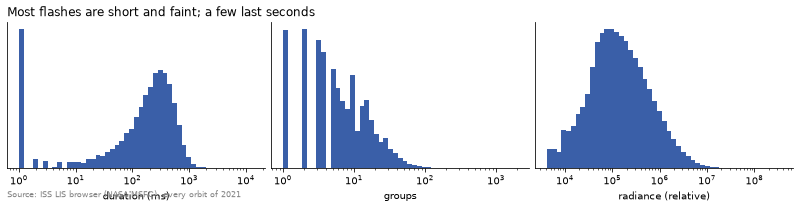

In [8]:
quantiles = flashes[["ms", "groups", "events", "radiance"]].quantile([0.5, 0.9, 0.99, 1]).T
quantiles.columns = ["median", "90%", "99%", "max"]
print(quantiles.to_string(float_format=lambda x: f"{x:,.0f}"))

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), constrained_layout=True)
for ax, column, label in zip(axes, ["ms", "groups", "radiance"], ["duration (ms)", "groups", "radiance (relative)"]):
    values = flashes[column].clip(lower=1)
    ax.hist(values, bins=np.logspace(np.log10(values.min()), np.log10(values.max()), 50), color=FLASH_COLOR)
    ax.set(xscale="log", xlabel=label, yticks=[])
axes[0].set_title("Most flashes are short and faint; a few last seconds", loc="left")
source_note(axes[0], f"Source: ISS LIS browser (NASA MSFC), every orbit of {YEAR}")

At the median a flash lasts about a fifth of a second and is made of 6 groups; 99 in 100 last under a second. The longest lasts over 13 seconds. Flashes listed at 0 ms are drawn at 1 ms.

## 4. A fair count: how long each latitude is watched

[5011](https://svs.gsfc.nasa.gov/5011/) · [ISS LIS browser](https://lightning.nsstc.nasa.gov/isslisib/)

The station circles on an orbit inclined 51.64° every 92.68 minutes. Its ground track hurries across the equator and lingers near 51.6° N and S, so the sensor watches some latitudes longer than others. Counting flashes as they come would crowd the lightning toward the turning latitudes. Each flash is weighed by how long its latitude is watched (ours): the share of the orbit on which the sensor's view (about 2.7° either side of the track) covers a band 2° wide around it, relative to the equator.

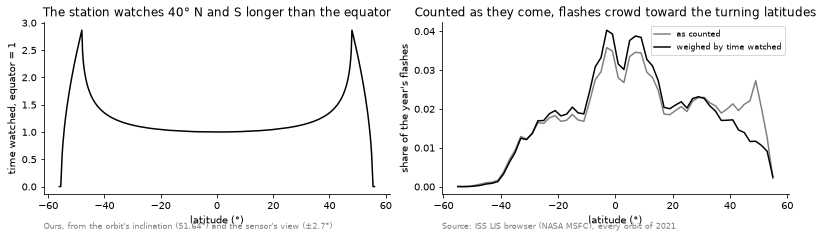

In [9]:
INCLINATION = math.radians(51.64)
PERIOD_SEC = 92.68 * 60
ORBITS_PER_DAY = 86400 / PERIOD_SEC
HALF_VIEW_DEG = 2.7
LAT_BIN = 2


def exposure(lats):
    """How much of the time the sensor's view covers each latitude in `lats` (a LAT_BIN wide band about it)."""
    u = np.linspace(0, 2 * np.pi, 200_001)
    track_lat = np.degrees(np.arcsin(np.sin(INCLINATION) * np.sin(u)))
    return np.array([np.mean(np.abs(track_lat - lat) <= LAT_BIN / 2 + HALF_VIEW_DEG) for lat in lats])


FINE = np.arange(-56, 56.25, 0.25)
FINE_EXPOSURE = exposure(FINE)


def latitude_weight(lats):
    """Each flash's weight: 1 at the equator, less where the station looks longer."""
    return FINE_EXPOSURE[len(FINE) // 2] / np.interp(lats, FINE, FINE_EXPOSURE)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
axes[0].plot(FINE, FINE_EXPOSURE / FINE_EXPOSURE[len(FINE) // 2], color="black")
axes[0].set(title="The station watches 40° N and S longer than the equator", xlabel="latitude (°)", ylabel="time watched, equator = 1")
counts, edges = np.histogram(flashes.lat, bins=np.arange(-56, 58, 2))
weighted, _ = np.histogram(flashes.lat, bins=edges, weights=latitude_weight(flashes.lat.values))
centres = (edges[:-1] + edges[1:]) / 2
axes[1].plot(centres, counts / counts.sum(), color="gray", label="as counted")
axes[1].plot(centres, weighted / weighted.sum(), color="black", label="weighed by time watched")
axes[1].set(title="Counted as they come, flashes crowd toward the turning latitudes", xlabel="latitude (°)", ylabel="share of the year's flashes")
axes[1].legend(fontsize=8)
source_note(axes[0], "Ours, from the orbit's inclination (51.64°) and the sensor's view (±2.7°)")
source_note(axes[1], f"Source: ISS LIS browser (NASA MSFC), every orbit of {YEAR}")

The station's passes also drift through the hours of the day: the hour at which it passes over a place runs through the whole day in about two months. Lightning over land is busiest in the afternoon, so a count over too few days would measure the hour of the passes rather than the season. The local solar time of the flashes within 15° of the equator, month by month (ours):

share of each month's flashes between 14 and 20 h: 48% 42% 45% 52% 37% 45% 34% 46% 55% 51% 52% 40%
share of the emptiest 2-hour slot: 2.4% 0.9% 2.5% 1.3% 2.8% 2.3% 1.2% 2.3% 2.0% 1.4% 1.3% 2.2%


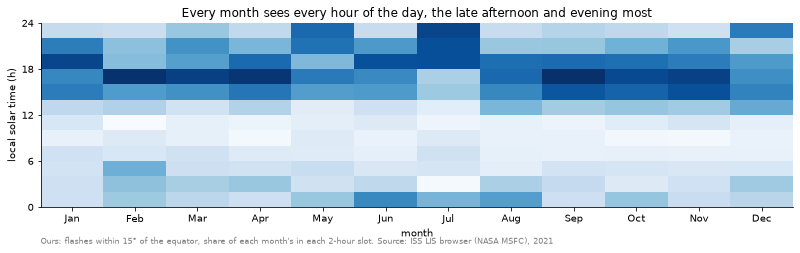

In [10]:
local_hour = (flashes.time.dt.hour + flashes.time.dt.minute / 60 + flashes.lon / 15) % 24
near_equator = flashes.lat.abs() < 15
hours = np.array([np.histogram(local_hour[near_equator & (flashes.day.dt.month == m)], bins=12, range=(0, 24))[0]
                  for m in range(1, 13)])
hour_share = hours / hours.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(11, 3.4), constrained_layout=True)
ax.imshow(hour_share.T, origin="lower", aspect="auto", cmap="Blues", extent=(0.5, 12.5, 0, 24))
ax.set(title="Every month sees every hour of the day, the late afternoon and evening most", xlabel="month", ylabel="local solar time (h)",
       yticks=range(0, 25, 6), xticks=range(1, 13), xticklabels=[date(YEAR, m, 1).strftime("%b") for m in range(1, 13)])
source_note(ax, f"Ours: flashes within 15° of the equator, share of each month's in each 2-hour slot. Source: ISS LIS browser (NASA MSFC), {YEAR}")
print("share of each month's flashes between 14 and 20 h:", " ".join(f"{s:.0%}" for s in hour_share[:, 7:10].sum(axis=1)))
print("share of the emptiest 2-hour slot:", " ".join(f"{s:.1%}" for s in hour_share.min(axis=1)))

Every month spreads its flashes near the equator over the whole day: no 2-hour slot holds much less than 1% of them, and the busiest hours, 14 to 20 h local time, hold 34% to 55%. A month of passes evens out the hour they come at. Ten days do not quite (in that time the passes over a place shift by only a few hours), so where a count of days could swing with the hour of the passes, section 5 sums 30 days (ours; EIC's roving window is 10 days).

## 5. The lightning belt follows the sun, late

[5011](https://svs.gsfc.nasa.gov/5011/) · [ISS LIS browser](https://lightning.nsstc.nasa.gov/isslisib/)

> "This data uncovers the variability and distribution of lightning"

EIC's year-long version of 5011 draws the equator and the two tropics over the lightning, without saying why the lightning moves. What we check (ours): does the latitude where lightning gathers follow the latitude the noon sun stands over, how far, and how late? Only the flashes within 40° of the equator are used; nearer the station's turning latitudes the correction for time watched swings too much.

### 5.1 The year's map

Every flash of 2021 within 40° of the equator in 2° cells, weighed by time watched.

on land: 79% of the flashes, weighed (the 1:110m coast is coarse, so some flashes near the shore count as sea)
by month: Jan 81% Feb 76% Mar 75% Apr 75% May 78% Jun 81% Jul 82% Aug 83% Sep 82% Oct 80% Nov 79% Dec 77%


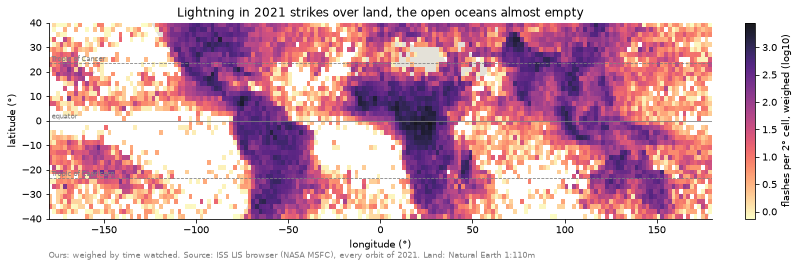

In [11]:
BELT_LAT = 40
belt = flashes[flashes.lat.abs() < BELT_LAT].copy()
belt["weight"] = latitude_weight(belt.lat.values)
lon_edges = np.arange(-180, 180 + LAT_BIN, LAT_BIN)
lat_edges = np.arange(-BELT_LAT, BELT_LAT + LAT_BIN, LAT_BIN)
lat_centres = (lat_edges[:-1] + lat_edges[1:]) / 2
grid, _, _ = np.histogram2d(belt.lon, belt.lat, bins=[lon_edges, lat_edges], weights=belt.weight)

fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
draw_land(ax)
mesh = ax.pcolormesh(lon_edges, lat_edges, np.ma.log10(np.ma.masked_equal(grid.T, 0)), cmap="magma_r", alpha=0.9)
ax.set(xlim=(-180, 180), ylim=(-BELT_LAT, BELT_LAT), xlabel="longitude (°)", ylabel="latitude (°)",
       title=f"Lightning in {YEAR} strikes over land, the open oceans almost empty")
draw_tropics(ax)
fig.colorbar(mesh, ax=ax, label="flashes per 2° cell, weighed (log10)")
source_note(ax, f"Ours: weighed by time watched. Source: ISS LIS browser (NASA MSFC), every orbit of {YEAR}. Land: Natural Earth 1:110m")

land_shape = shapely.union_all(land)
shapely.prepare(land_shape)
belt["on_land"] = shapely.contains_xy(land_shape, belt.lon.values, belt.lat.values)
month = belt.day.dt.month
on_land = (belt.on_land * belt.weight).groupby(month).sum() / belt.weight.groupby(month).sum()
print(f"on land: {np.average(belt.on_land, weights=belt.weight):.0%} of the flashes, weighed "
      "(the 1:110m coast is coarse, so some flashes near the shore count as sea)")
print("by month:", " ".join(f"{date(YEAR, m, 1):%b} {s:.0%}" for m, s in on_land.items()))

### 5.2 Where the belt sits, day by day

Dates across, latitude up. The colour is how each day's lightning is spread over the 2° bands, over the 30 days around it (weighed by time watched; each day is scaled on its own, so the colour shows where that day's lightning gathers, not how much there is).

- Orange: the latitude the noon sun stands over, on the equator on March 20 and September 23, the Tropic of Cancer on June 21 and the Tropic of Capricorn on December 21.
- Blue: the belt's centre, the mean latitude of its flashes.

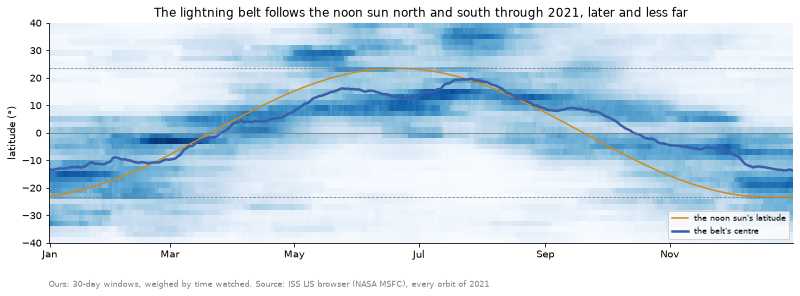

In [12]:
BELT_WINDOW_DAYS = 30
SUN_COLOR = "#d08a1e"


def subsolar(index):
    """The latitude the noon sun stands over on each day of `index`."""
    return TROPIC_DEG * np.sin(2 * np.pi * (index.day_of_year - 80) / 365.25)


def belt_map(d):
    """The weighed flashes of `d` by day (rows, every day of YEAR) and 2° band (columns), summed over the
    BELT_WINDOW_DAYS around each day; a day without orbits adds nothing."""
    band = pd.cut(d.lat, lat_edges, labels=lat_centres).astype(float)
    daily = d.weight.groupby([d.day, band]).sum().unstack(fill_value=0).reindex(index=DAYS, columns=lat_centres, fill_value=0)
    return daily.rolling(BELT_WINDOW_DAYS, center=True, min_periods=BELT_WINDOW_DAYS // 2).sum()


def centroid(h):
    """The belt's centre latitude on each day of a belt_map."""
    return (h * lat_centres).sum(axis=1) / h.sum(axis=1)


def draw_belt(ax, h, colour):
    ax.pcolormesh(DAYS, lat_centres, h.div(h.sum(axis=1), axis=0).T.to_numpy(), cmap="Blues", shading="nearest")
    ax.plot(DAYS, subsolar(DAYS), color=SUN_COLOR, label="the noon sun's latitude")
    ax.plot(DAYS, centroid(h), color=colour, linewidth=2.5, label="the belt's centre")
    for lat in (TROPIC_DEG, 0, -TROPIC_DEG):
        ax.axhline(lat, color="gray", linewidth=0.8, linestyle="-" if lat == 0 else "--")
    ax.set(ylim=(-BELT_LAT, BELT_LAT))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))


belt_days = belt_map(belt)
centre = centroid(belt_days)
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
draw_belt(ax, belt_days, FLASH_COLOR)
ax.set(title=f"The lightning belt follows the noon sun north and south through {YEAR}, later and less far", ylabel="latitude (°)")
ax.legend(loc="lower right", fontsize=8)
source_note(ax, f"Ours: 30-day windows, weighed by time watched. Source: ISS LIS browser (NASA MSFC), every orbit of {YEAR}")

How far and how late (ours): the sun's curve is delayed day by day, and the delay that best matches the belt's centre is kept (the highest correlation). How far is the slope of the belt's centre against the delayed sun: how many degrees the belt moves for each degree the sun does. Then the days the belt's centre crosses the equator, and the northern hemisphere's share of the belt's lightning, month by month.

In [13]:
def lag_fit(c):
    """(days, correlation, gain): the delay of the sun's latitude that best matches the belt's centre `c`, and how
    many degrees the belt moves for each degree the sun does."""
    ok = c.notna().to_numpy()
    best = None
    for lag in range(-30, 91):
        sun = np.asarray(subsolar(c.index - pd.Timedelta(days=lag)))[ok]
        r = np.corrcoef(sun, c[ok])[0, 1]
        if best is None or r > best[1]:
            best = (lag, r, np.polyfit(sun, c[ok], 1)[0])
    return best


lag, r, gain = lag_fit(centre)
print(f"the belt's centre is {lag} days behind the sun (correlation {r:.2f}) and moves {gain:.2f}° for each degree "
      f"the sun does; it runs from {centre.min():.1f}° to {centre.max():.1f}° (the sun ±{TROPIC_DEG}°)")
north = centre.dropna() > 0
for day, northward in north[north.ne(north.shift())].iloc[1:].items():
    print(f"  the belt's centre crosses the equator {'northward' if northward else 'southward'} on {day:%b %d}")
print("  (the sun crosses northward on Mar 20 and southward on Sep 23)")
belt_north = ((belt.lat > 0) * belt.weight).groupby(month).sum() / belt.weight.groupby(month).sum()
print("northern share of the belt's lightning:", " ".join(f"{date(YEAR, m, 1):%b} {s:.0%}" for m, s in belt_north.items()))

the belt's centre is 18 days behind the sun (correlation 0.99) and moves 0.64° for each degree the sun does; it runs from -13.7° to 19.7° (the sun ±23.44°)
  the belt's centre crosses the equator northward on Mar 27
  the belt's centre crosses the equator southward on Oct 15
  (the sun crosses northward on Mar 20 and southward on Sep 23)
northern share of the belt's lightning: Jan 17% Feb 19% Mar 41% Apr 65% May 84% Jun 86% Jul 92% Aug 80% Sep 68% Oct 46% Nov 33% Dec 15%


### 5.3 Region by region

Lightning strikes over land, so the three landmasses are measured apart, split by longitude (ours): the Americas (130° W to 30° W), Africa and Europe (30° W to 60° E), and Asia and Australia (60° E to 180°).

,flashes,days behind the sun,correlation,° per ° of sun,southernmost (°),northernmost (°)
The Americas,"266,002",17,0.97,0.73,-17.1,21.6
Africa and Europe,"300,955",31,0.97,0.45,-14.5,13.0
Asia and Australia,"232,942",13,0.97,0.83,-18.5,24.8


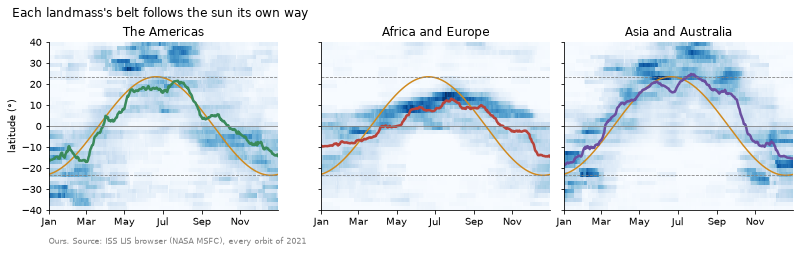

In [14]:
class Region(Enum):
    # (name, western longitude, eastern longitude, colour): the three landmasses lightning gathers over.
    AMERICAS = ("The Americas", -130, -30, "#3a8a5c")
    AFRICA_EUROPE = ("Africa and Europe", -30, 60, "#b8433a")
    ASIA_AUSTRALIA = ("Asia and Australia", 60, 180, "#6a4fa0")

    @property
    def title(self):
        return self.value[0]

    @property
    def colour(self):
        return self.value[3]

    def has(self, lon):
        return (lon >= self.value[1]) & (lon < self.value[2])


fig, axes = plt.subplots(1, len(Region), figsize=(11, 3.4), sharey=True, constrained_layout=True)
summary = {}
for ax, region in zip(axes, Region):
    d = belt[region.has(belt.lon)]
    h = belt_map(d)
    c = centroid(h)
    region_lag, region_r, region_gain = lag_fit(c)
    summary[region.title] = {"flashes": f"{len(d):,}", "days behind the sun": region_lag, "correlation": round(region_r, 2),
                             "° per ° of sun": round(region_gain, 2), "southernmost (°)": round(c.min(), 1),
                             "northernmost (°)": round(c.max(), 1)}
    draw_belt(ax, h, region.colour)
    ax.set(title=region.title)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set_ylabel("latitude (°)")
fig.suptitle("Each landmass's belt follows the sun its own way", x=0.01, ha="left")
source_note(axes[0], f"Ours. Source: ISS LIS browser (NASA MSFC), every orbit of {YEAR}")
pd.DataFrame(summary).T

What the year shows (ours):

1. **South in January, north in July.** The lightning gathers in one hemisphere at each end of the year: in January 83% of the belt's lightning strikes in the south, in July 92% in the north (15% north again in December). Its centre moves with the latitude of the noon sun (correlation 0.99), north in the northern summer and south in the southern one.
2. **Late and not as far.** The best match is the sun 18 days earlier, and the belt moves 0.64° for each degree the sun does: from 13.7° S to 19.7° N, short of the tropics (±23.44°).
3. **Later in autumn than in spring.** The belt's centre crosses the equator northward on March 27, a week after the sun, and southward on October 15, three weeks after it; through September and October it lingers north of the equator.
4. **Each landmass its own way.**
   - Africa and Europe: the narrowest (14.5° S to 13.0° N, 0.45° per degree of sun) and the latest (31 days); much of Africa's lightning stays near the equator all year.
   - The Americas: wide (17.1° S to 21.6° N, 0.73°), 17 days late.
   - Asia and Australia: the closest follower (13 days, 0.83°), reaching furthest north (24.8° N) as the Asian monsoon builds, and south over northern Australia and Indonesia in the southern summer.
5. **Over land.** 79% of the flashes, weighed, fall on land, 75% to 83% each month (the 1:110m coast is coarse, so some flashes near the shore count as sea).

Limits: one year (2021) only; whether the belt moves the same way every year, or differently in an El Niño year, needs other years. The radiance has no unit in the table and is compared only with itself.

## 6. The season: lightning follows the summer

[5011](https://svs.gsfc.nasa.gov/5011/) · [ISS LIS browser](https://lightning.nsstc.nasa.gov/isslisib/)

> "A roving window of 10 days was used to visualize the seasonal patterns of lightning."

The album's globe looks at the equator from one side of the Earth, so both hemispheres are in sight, and only the flashes within 70° of the centre of view are kept (beyond, the disc is squeezed at its edge). Two sides are played (ours):

- **The Americas and Africa**, centred on 25° W, close to the longitude whose view holds the most lightning.
- **Asia and Australia**, centred on 110° E: South and East Asia above, Australia below. The opposite side of the first (155° E) is mostly the Pacific and holds too little lightning, and a view nearer Europe has Africa below it. Africa's east still reaches into this view, so flashes west of 52° E (just past Cape Hafun, 51.4° E, Africa's easternmost point) are left out.

How much of the lightning each longitude's view holds, weighed by time watched, against the busiest:

busiest view: -30°; -25°: 99%, 110°: 53%, 155°: 38%


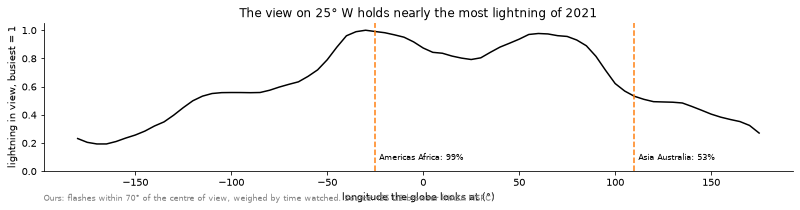

In [15]:
VIEW_REACH_DEG = 70


class Side(Enum):
    # (the longitude the globe looks at on the equator, the westernmost longitude of the flashes kept or None)
    AMERICAS_AFRICA = (-25, None)
    ASIA_AUSTRALIA = (110, 52)

    @property
    def lon(self):
        return self.value[0]

    def sees(self, lat, lon):
        """Whether each flash lies within VIEW_REACH_DEG of this side's centre (and east of its western limit)."""
        lat, lon = np.asarray(lat), np.asarray(lon)
        near = np.cos(np.radians(lat)) * np.cos(np.radians(lon - self.lon)) > np.cos(np.radians(VIEW_REACH_DEG))
        west = self.value[1]
        return near if west is None else near & (lon >= west)


def in_view(centre_lon, lat, lon):
    return np.cos(np.radians(lat)) * np.cos(np.radians(lon - centre_lon)) > np.cos(np.radians(VIEW_REACH_DEG))


weight = latitude_weight(flashes.lat.values)
scan = pd.Series({c: weight[in_view(c, flashes.lat.values, flashes.lon.values)].sum() for c in range(-180, 180, 5)})
scan /= scan.max()
fig, ax = plt.subplots(figsize=(11, 2.8), constrained_layout=True)
ax.plot(scan.index, scan.values, color="black")
for side in Side:
    ax.axvline(side.lon, color="tab:orange", linestyle="--")
    ax.annotate(f"{side.name.replace('_', ' ').title()}: {scan[side.lon]:.0%}", (side.lon, 0.08), xytext=(4, 0), textcoords="offset points", fontsize=8)
ax.set(title=f"The view on 25° W holds nearly the most lightning of {YEAR}", xlabel="longitude the globe looks at (°)", ylabel="lightning in view, busiest = 1", ylim=(0, 1.05))
source_note(ax, f"Ours: flashes within {VIEW_REACH_DEG}° of the centre of view, weighed by time watched. Source: ISS LIS browser (NASA MSFC)")
print(f"busiest view: {scan.idxmax()}°;", ", ".join(f"{lon}°: {scan[lon]:.0%}" for lon in (-25, 110, 155)))

Each day, each hemisphere's lightning in view (ours): the flashes weighed by time watched and added up, then scaled to a full day's orbits (15.5) because the browser lacks some orbits on a few days. A day without orbits stays empty.

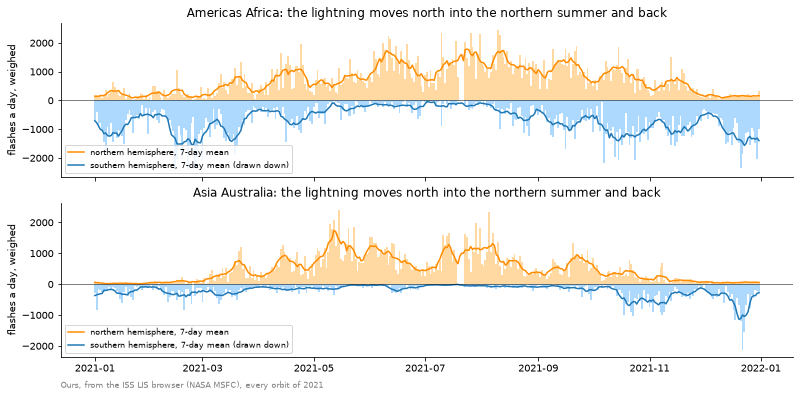

In [16]:
def hemisphere_days(side):
    """Each day's lightning in view of `side`, by hemisphere: a DataFrame of `north` and `south`, NaN on a day
    without orbits."""
    seen = flashes[side.sees(flashes.lat, flashes.lon)]
    hemisphere = np.where(seen.lat >= 0, "north", "south")
    amount = (pd.Series(latitude_weight(seen.lat.values), index=seen.index)
              .groupby([seen.day, hemisphere]).sum().unstack(fill_value=0).reindex(DAYS, fill_value=0))
    return amount.mul(ORBITS_PER_DAY / per_day.replace(0, np.nan), axis=0)[["north", "south"]]


days = {side: hemisphere_days(side) for side in Side}
NORTH_COLOR, SOUTH_COLOR = "#ffb347", "#5fb4ff"
fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, constrained_layout=True)
for ax, (side, h) in zip(axes, days.items()):
    week = h.rolling(7, center=True, min_periods=1).mean()
    ax.bar(h.index, h.north, width=1, color=NORTH_COLOR, alpha=0.5)
    ax.bar(h.index, -h.south, width=1, color=SOUTH_COLOR, alpha=0.5)
    ax.plot(week.index, week.north, color="darkorange", label="northern hemisphere, 7-day mean")
    ax.plot(week.index, -week.south, color="tab:blue", label="southern hemisphere, 7-day mean (drawn down)")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set(title=f"{side.name.replace('_', ' ').title()}: the lightning moves north into the northern summer and back",
           ylabel="flashes a day, weighed")
    ax.legend(fontsize=8, loc="lower left")
source_note(axes[1], f"Ours, from the ISS LIS browser (NASA MSFC), every orbit of {YEAR}")

Where each side's lightning is, in January, April, July and October (ours): northern flashes orange, southern flashes blue.

Text(0.01, 0.01, "Ours: flashes within 70° of each side's centre. Source: ISS LIS browser (NASA MSFC). Land: Natural Earth 1:110m")

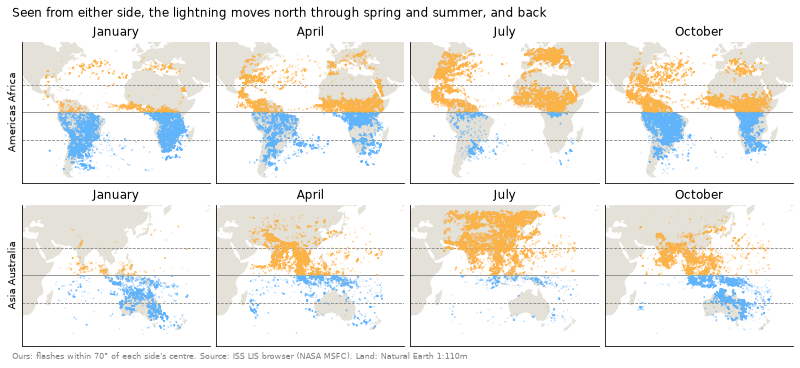

In [17]:
fig, axes = plt.subplots(len(Side), 4, figsize=(11, 5), constrained_layout=True)
for row, side in zip(axes, Side):
    seen = flashes[side.sees(flashes.lat, flashes.lon)]
    lon = (seen.lon - side.lon + 180) % 360 - 180 + side.lon
    for ax, m in zip(row, (1, 4, 7, 10)):
        shown = (seen.day.dt.month == m).to_numpy()
        draw_land(ax, shifts=(-360, 0, 360))
        ax.set(xlim=(side.lon - 90, side.lon + 90), ylim=(-60, 60), xticks=[], yticks=[], title=f"{date(YEAR, m, 1):%B}")
        draw_tropics(ax, names=False)
        ax.scatter(lon[shown], seen.lat[shown], s=0.3, alpha=0.3, rasterized=True,
                   c=np.where(seen.lat[shown] >= 0, NORTH_COLOR, SOUTH_COLOR))
    row[0].set_ylabel(side.name.replace("_", " ").title())
fig.suptitle("Seen from either side, the lightning moves north through spring and summer, and back", x=0.01, ha="left")
fig.supxlabel(f"Ours: flashes within {VIEW_REACH_DEG}° of each side's centre. Source: ISS LIS browser (NASA MSFC). Land: Natural Earth 1:110m", x=0.01, ha="left", fontsize=8, color="gray")

The northern hemisphere's share of each side's lightning, month by month (ours):

In [18]:
def north_share_by_month(h):
    month = h.index.month
    return h.north.groupby(month).sum() / h.sum(axis=1).groupby(month).sum()


share = pd.DataFrame({side.name.replace("_", " ").title(): north_share_by_month(h) for side, h in days.items()}).T
share.columns = [date(YEAR, m, 1).strftime("%b") for m in share.columns]
share.style.format("{:.0%}")

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Americas Africa,18%,18%,33%,58%,72%,87%,90%,76%,61%,44%,35%,13%
Asia Australia,10%,22%,60%,81%,92%,89%,96%,91%,83%,50%,26%,10%


The days the lead changes hands (ours): the day the northern hemisphere's 7-day mean overtakes the southern one, or falls back below it, and stays there for at least 10 days, so days of wavering around the turn count once.

In [19]:
CROSSING_HOLD_DAYS = 10


def crossings(h):
    """(day, True when the north takes the lead) for each lasting change of lead in `h`'s 7-day means."""
    week = h.rolling(7, center=True, min_periods=1).mean()
    leads = (week.north > week.south).to_numpy()
    out, current = [], leads[0]
    for i in range(1, len(leads)):
        if leads[i] != current and (leads[i:i + CROSSING_HOLD_DAYS] == leads[i]).all():
            current = leads[i]
            out.append((week.index[i], bool(current)))
    return out


for side, h in days.items():
    print(f"{side.name.replace('_', ' ').title()}: " + ", ".join(
        f"{'north' if north else 'south'} leads from {day:%b %d}" for day, north in crossings(h)))

Americas Africa: north leads from Apr 02, south leads from Oct 04
Asia Australia: north leads from Mar 14, south leads from Oct 16


- On both sides the lightning sits in the southern hemisphere in its summer (December to February) and in the northern hemisphere in its summer (June to August).
- The lead changes hands twice a year, in spring and autumn. Over Asia and Australia it changes faster and swings further north, as the Asian monsoon builds.

## 7. Message summary

| EIC page | Message | Key numbers | Track data |
| --- | --- | --- | --- |
| [5011](https://svs.gsfc.nasa.gov/5011/) | "A roving window of 10 days was used to visualize the seasonal patterns of lightning." | The northern share by month and the days the lead changes hands (section 6, ours); 83% of the lightning in the south in January and 92% in the north in July, and the belt's lag behind the noon sun (section 5, ours) | Each side's daily lightning by hemisphere, the noon sun's latitude, and a sample of the flashes in view |

## 8. Tracks

One track per side, the year 2021 from January 1 to the midnight after December 31. Each track file holds, in time order within each kind of row:

- `north`, `south`: each day (and the midnight after the last), how much lightning the hemisphere had in view: the 7-day mean around the day, as a share of the side's busiest hemisphere-day, square-rooted (as loudness is heard), so each track's balance between its hemispheres is heard in full whichever side has more lightning. A day without orbits takes the mean of the days around it.
- `sun`: the same days, the latitude the noon sun stands over.
- `flash`: the flashes the globe draws and the music plays: a sample of about 60,000 of the flashes in view, each kept with a chance that falls where the station looks longer, so the sample is weighed by time watched.

The longitude the globe looks at goes into `tracks.json` as each track's `view`.

In [20]:
LEVEL_DAYS = 7
FLASHES_KEPT = 60_000
SEED = 2021
HEMISPHERES = ["north", "south"]
TRACK_DAYS = DAYS.append(pd.DatetimeIndex([DAYS[-1] + pd.Timedelta(days=1)]))
TITLE = {Side.AMERICAS_AFRICA: "The Americas and Africa", Side.ASIA_AUSTRALIA: "Asia and Australia"}
FILE = {side: f"{side.name.lower()}_{YEAR}.csv" for side in Side}


def iso(timestamp):
    """UTC to the hundredth of a second, as the browser gives it."""
    return pd.Timestamp(timestamp).strftime("%Y-%m-%dT%H:%M:%S.%f")[:-4] + "Z"


def track_rows(side, rng):
    level = days[side].rolling(LEVEL_DAYS, center=True, min_periods=1).mean()
    level = np.sqrt(level / level.to_numpy().max()).reindex(TRACK_DAYS, method="ffill")
    rows = [(iso(day), h, "", "", round(float(level.at[day, h]), 4)) for h in HEMISPHERES for day in TRACK_DAYS]
    rows += [(iso(day), "sun", round(float(lat), 2), "", "") for day, lat in zip(TRACK_DAYS, subsolar(TRACK_DAYS))]
    seen = flashes[side.sees(flashes.lat, flashes.lon)]
    weight = latitude_weight(seen.lat.values)
    shown = seen[rng.random(len(seen)) < weight * FLASHES_KEPT / weight.sum()].sort_values("time")
    rows += [(iso(t), "flash", round(lat, 2), round(lon, 2), "") for t, lat, lon in zip(shown.time, shown.lat, shown.lon)]
    return pd.DataFrame(rows, columns=["time", "kind", "lat_deg", "lon_deg", "level"]), len(seen), len(shown)


rng = np.random.default_rng(SEED)
TRACKS.mkdir(parents=True, exist_ok=True)
for side in Side:
    table, seen_count, shown_count = track_rows(side, rng)
    table.to_csv(TRACKS / FILE[side], index=False)
    print(f"{FILE[side]}: {seen_count:,} flashes in view, {shown_count:,} drawn, "
          f"{(TRACKS / FILE[side]).stat().st_size / 1e6:.2f} MB")

americas_africa_2021.csv: 539,419 flashes in view, 59,879 drawn, 2.63 MB


asia_australia_2021.csv: 287,006 flashes in view, 59,806 drawn, 2.64 MB


Each track's sources, credit and message go into `tracks.json`.

In [21]:
DOWNLOADED_ON = date.fromtimestamp(min(p.stat().st_mtime for p in LIS_DIR.glob("day_*.html"))).isoformat()
EIC_MESSAGE = "A roving window of 10 days was used to visualize the seasonal patterns of lightning."
assert EIC_MESSAGE in " ".join(descriptions(5011))
LIS_SOURCE = {
    "source": "Quality Controlled Lightning Imaging Sensor (LIS) on International Space Station (ISS) Science Data, through the ISS LIS browser of NASA MSFC",
    "sourceUrl": LISIB,
    "downloadUrl": f"{LISIB}lis1orbit.exe?which=qc&year={YEAR}&day=<day>&orbit=<hhmmss>",
    "version": "3.0 (quality controlled)",
    "doi": LIS_V3,
    "downloaded": DOWNLOADED_ON,
    "license": "NASA data, no restrictions on use",
    "credit": "Blakeslee, R. J., et al. Lightning Imaging Sensor (LIS) on the International Space Station (ISS). NASA GHRC DAAC / NASA MSFC.",
    "substitute": "EIC cites V1 of the same dataset; its link no longer answers, and V3.0 on GHRC needs an Earthdata login. The browser prints the same quality-controlled flashes publicly, one table per orbit.",
}
entries = [{
    "file": FILE[side],
    "title": TITLE[side],
    "pages": [{"svsId": 5011, "svsUrl": "https://svs.gsfc.nasa.gov/5011/", "message": EIC_MESSAGE}],
    "note": ("Ours: the flashes within 70° of where the globe looks on the equator"
             + (", east of 52° E" if side.value[1] else "")
             + ", weighed by how long the station watches each latitude, split between the hemispheres; each "
             "hemisphere's daily amount as a 7-day mean, a share of the side's busiest hemisphere-day, square-rooted; "
             "the noon sun's latitude; a weighed sample of the flashes."),
    "sources": [LIS_SOURCE],
    "view": {"lat": 0, "lon": side.lon},
    "units": {"lat_deg": "degrees north", "lon_deg": "degrees east",
              "level": "share of the track's busiest hemisphere-day, square-rooted (0 to 1)"},
    "timeRange": [TRACK_DAYS[0].strftime("%Y-%m-%d"), TRACK_DAYS[-1].strftime("%Y-%m-%d")],
} for side in Side]
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
print(json.dumps(entries[0], indent=2)[:1200])

{
  "file": "americas_africa_2021.csv",
  "title": "The Americas and Africa",
  "pages": [
    {
      "svsId": 5011,
      "svsUrl": "https://svs.gsfc.nasa.gov/5011/",
      "message": "A roving window of 10 days was used to visualize the seasonal patterns of lightning."
    }
  ],
  "note": "Ours: the flashes within 70\u00b0 of where the globe looks on the equator, weighed by how long the station watches each latitude, split between the hemispheres; each hemisphere's daily amount as a 7-day mean, a share of the side's busiest hemisphere-day, square-rooted; the noon sun's latitude; a weighed sample of the flashes.",
  "sources": [
    {
      "source": "Quality Controlled Lightning Imaging Sensor (LIS) on International Space Station (ISS) Science Data, through the ISS LIS browser of NASA MSFC",
      "sourceUrl": "https://lightning.nsstc.nasa.gov/isslisib/",
      "downloadUrl": "https://lightning.nsstc.nasa.gov/isslisib/lis1orbit.exe?which=qc&year=2021&day=<day>&orbit=<hhmmss>",
    